# <b>Synthetic liquidation features for BTC toxic-flow filtering.</b>

This notebook investigates whether features generated using a conditional diffusion model can improve the out-of-sample filter for toxic maker flow on ETH.

The base model is `lgbm_huber`, trained on the `top 10 features` from the best BTC run. These features primarily describe recent liquidation flow, signed liquidation pressure, realised volatility, VPIN and time-of-day effects.

A set of `synthetic features` derived from the `diffusion model` is added to the baseline model. The diffusion model is `trained solely on the train portion`  of each walk-forward window and generates possible future liquidation paths. Features for tail liquidation risk are then constructed from these synthetic paths:

- diff2ch_p90_dollar_liq_30s
- diff2ch_p95_dollar_liq_30s
- diff2ch_p90_dollar_liq_120s
- diff2ch_p95_dollar_liq_120s
- diff2ch_p90_dollar_liq_300s
- diff2ch_p95_dollar_liq_300s

It is important to note that synthetic forecasts are `not generated for every trade or every liquidation event`. To save time, the forecast is based only on a selected grid of forecast anchors, after which the features are linked to the trades via the last available forecast. As a result, some trades receive an out-of-date forecast, and in certain periods the synthetic features become sparse and less locally informative.

Therefore, this experiment is not the final production version of the diffusion pipeline, but an initial test of the hypothesis:
“Does the forecast of the distribution of future liquidations contain an additional signal for PnL-based toxic-flow filtering?”


## <b>Imports.</b>

In [1]:
from pathlib import Path
from experiment import (
    WalkForwardConfig,
    walk_forward
)
from splits import get_window_ids
import utilities as util

In [2]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"X does not have valid feature names, but LGBMRegressor was fitted with feature names",
    category=UserWarning
)

## <b>0. Config.</b>

In [20]:
INSTRUMENT = "btc"
MODEL_NAME = "lgbm_huber"
HORIZONS = [30, 120, 300]

MAX_FILTER_RATES = [0.99, 0.995, 0.999]
FOCUS_FILTER_RATE = 0.99

# Grab features with synthetic data.
SPLIT_DIR = Path(f"data/meta/{INSTRUMENT}_splits_diff2ch")

# Top 10 features from file 3.ETH_Results.ipunb.
BASE_FEATURES = [
    "vpin_120s",
    "signed_liq_bybit_120s",
    "hour",
    "liq_bybit_120s",
    "rv_120s",
    "signed_liq_binance_30s",
    "liq_binance_30s",
    "signed_liq_binance_120s",
    "liq_binance_120s",
    "liq_aligned_5s"
]

DIFF = [
    "diff2ch_p90_dollar_liq_30s",
    "diff2ch_p95_dollar_liq_30s",
    "diff2ch_p90_dollar_liq_120s",
    "diff2ch_p95_dollar_liq_120s",
    "diff2ch_p90_dollar_liq_300s",
    "diff2ch_p95_dollar_liq_300s"
]

print("SPLIT_DIR:", SPLIT_DIR)
print("exists:", SPLIT_DIR.exists())
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

SPLIT_DIR: data\meta\btc_splits_diff2ch
exists: True
Base features (10): ['vpin_120s', 'signed_liq_bybit_120s', 'hour', 'liq_bybit_120s', 'rv_120s', 'signed_liq_binance_30s', 'liq_binance_30s', 'signed_liq_binance_120s', 'liq_binance_120s', 'liq_aligned_5s']


## <b>1. Walk-Forward.<b>

In [4]:
feature_variants = {
    "base": BASE_FEATURES,
    "diff_all": BASE_FEATURES + DIFF
}

results_ablation = {}

for tau in HORIZONS:
    for variant, feat_list in feature_variants.items():
        print(f"{INSTRUMENT.upper()} | {MODEL_NAME} | {variant} | tau={tau}s")

        config = WalkForwardConfig(
            instrument       = INSTRUMENT,
            tau              = tau,
            model_name       = MODEL_NAME,
            max_filter_rates = MAX_FILTER_RATES,
            window_ids       = get_window_ids(),
            verbose          = False,
            use_tqdm         = True
        )

        results_ablation[(variant, tau)] = walk_forward(
            config    = config,
            features  = feat_list,
            split_dir = SPLIT_DIR
        )

BTC | lgbm_huber | base | tau=30s


WF btc lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

BTC | lgbm_huber | diff_all | tau=30s


WF btc lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

BTC | lgbm_huber | base | tau=120s


...

WF btc lgbm_huber tau=120s:   0%|          | 0/5 [00:00<?, ?it/s]

BTC | lgbm_huber | base | tau=300s


WF btc lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

BTC | lgbm_huber | diff_all | tau=300s


WF btc lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

## <b>2. Summary tables.</b>

In [21]:
summary_ablation = util.build_wf_summary_table(
    results         = results_ablation,
    max_filter_rate = FOCUS_FILTER_RATE
)

summary_ablation

,variant,tau,window,max_filter_rate,pnl_all,pnl_kept,pnl_filtered,score,"kept_turnover_per_day, mln$",turnover_ok,filter_rate
0,base,30,W1,0.99,-0.102400,3.553586,-0.175977,3.655986,5.16,True,0.9876
1,base,30,W2,0.99,-0.106321,1.557817,-0.183186,1.664138,12.23,True,0.9714
2,base,30,W3,0.99,-0.157706,4.129037,-0.184838,4.286743,1.84,True,0.9969
3,base,30,W4,0.99,-0.157633,-8.103497,-0.057210,-7.945864,3.74,True,0.9934
4,base,30,W5,0.99,-0.085905,-0.085905,0.000000,0.000000,247.65,True,0.0000
5,base,120,W1,0.99,0.001451,1.808734,-0.033697,1.807282,4.99,True,0.9876
6,base,120,W2,0.99,0.096189,13.931580,-0.303710,13.835390,7.78,True,0.9816
7,base,120,W3,0.99,-0.242931,5.443267,-0.291503,5.686198,2.47,True,0.9948
8,base,120,W4,0.99,-0.209618,-0.710589,-0.203605,-0.500971,3.55,True,0.9931
9,base,120,W5,0.99,0.050937,4.986883,-0.080712,4.935946,6.43,True,0.9833


## <b>3. Chart with Scores.</b>

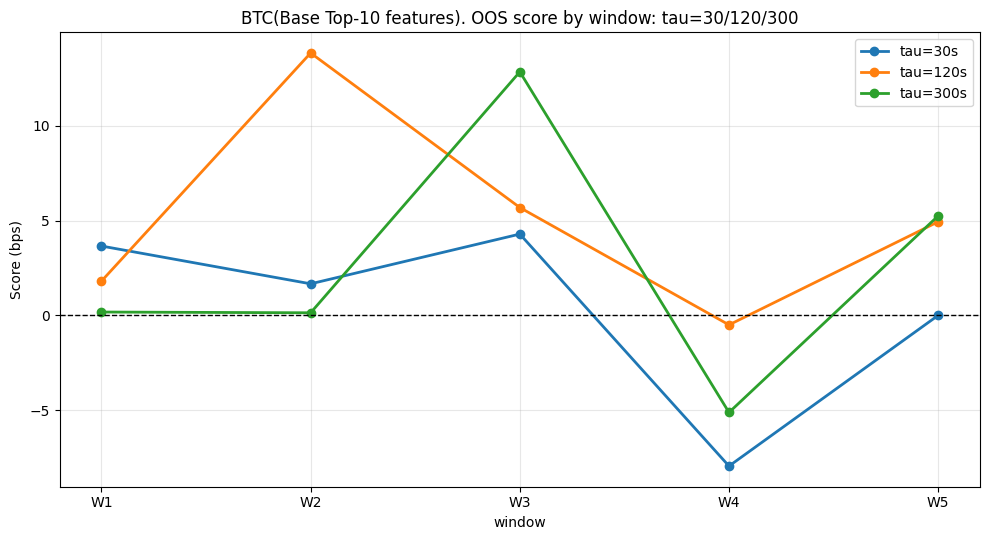

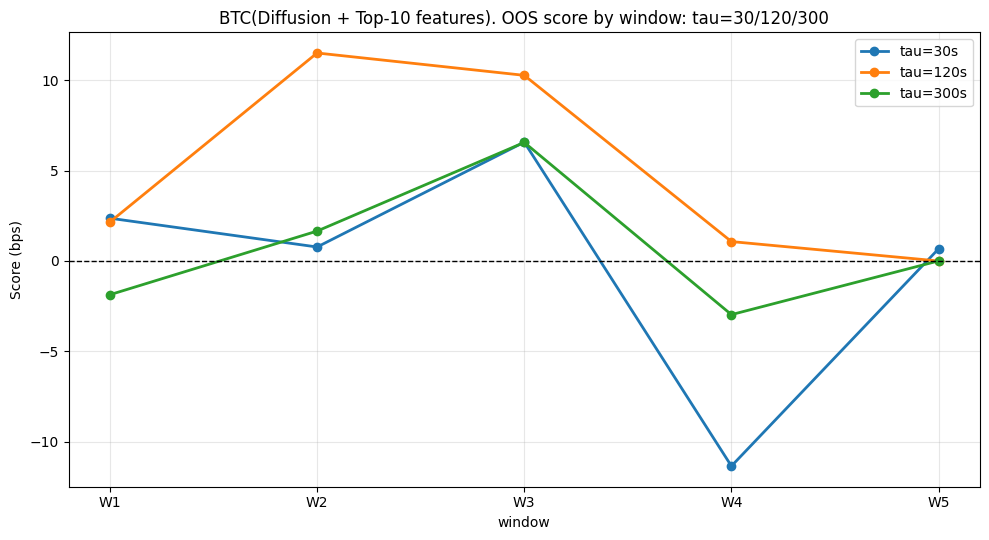

In [ ]:
pivot_scores_base = util.plot_score_by_window_one_chart(
    summary_table       = summary_ablation,
    variant             = "base",
    taus                = (30, 120, 300),
    title               = "BTC(Base Top-10 features). OOS score by window: tau=30/120/300"
)

pivot_scores_diff = util.plot_score_by_window_one_chart(
    summary_table       = summary_ablation,
    variant             = "diff_all",
    taus                = (30, 120, 300),
    title               = "BTC(Diffusion + Top-10 features). OOS score by window: tau=30/120/300"
)

## <b>4. Distribution charts.</b>

BTC_lgbm_huber_base_tau120s_fr0.99
Daily Score:
  mean   = +5.663583
  std    = 11.842097
  median = +5.579674
  min    = -24.951301
  max    = +44.294447
  >0 days: 74/109 (68%)
  <0 days: 35/109 (32%)

BTC_lgbm_huber_base_tau120s_fr0.99
Daily PnL kept:
  mean   = +5.608785
  std    = 11.999020
  median = +5.606883
  min    = -26.031171
  max    = +44.086641
  >0 days: 73/109 (67%)
  <0 days: 36/109 (33%)



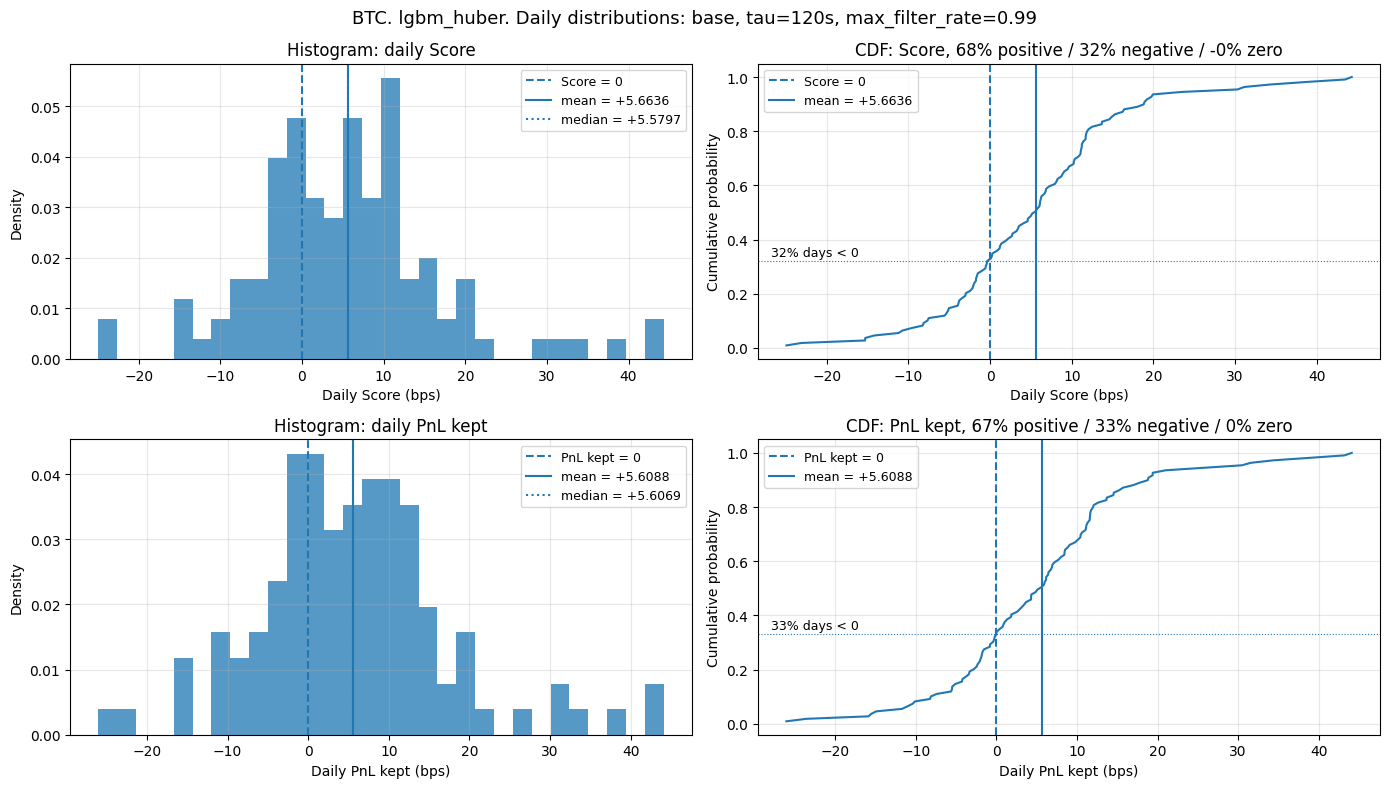

BTC_lgbm_huber_diff_all_tau120s_fr0.99
Daily Score:
  mean   = +3.859627
  std    = 10.004039
  median = +0.858775
  min    = -26.834275
  max    = +53.858948
  >0 days: 62/108 (57%)
  <0 days: 25/108 (23%)

BTC_lgbm_huber_diff_all_tau120s_fr0.99
Daily PnL kept:
  mean   = +3.800712
  std    = 10.141657
  median = +1.170498
  min    = -27.305896
  max    = +53.587076
  >0 days: 72/108 (67%)
  <0 days: 36/108 (33%)



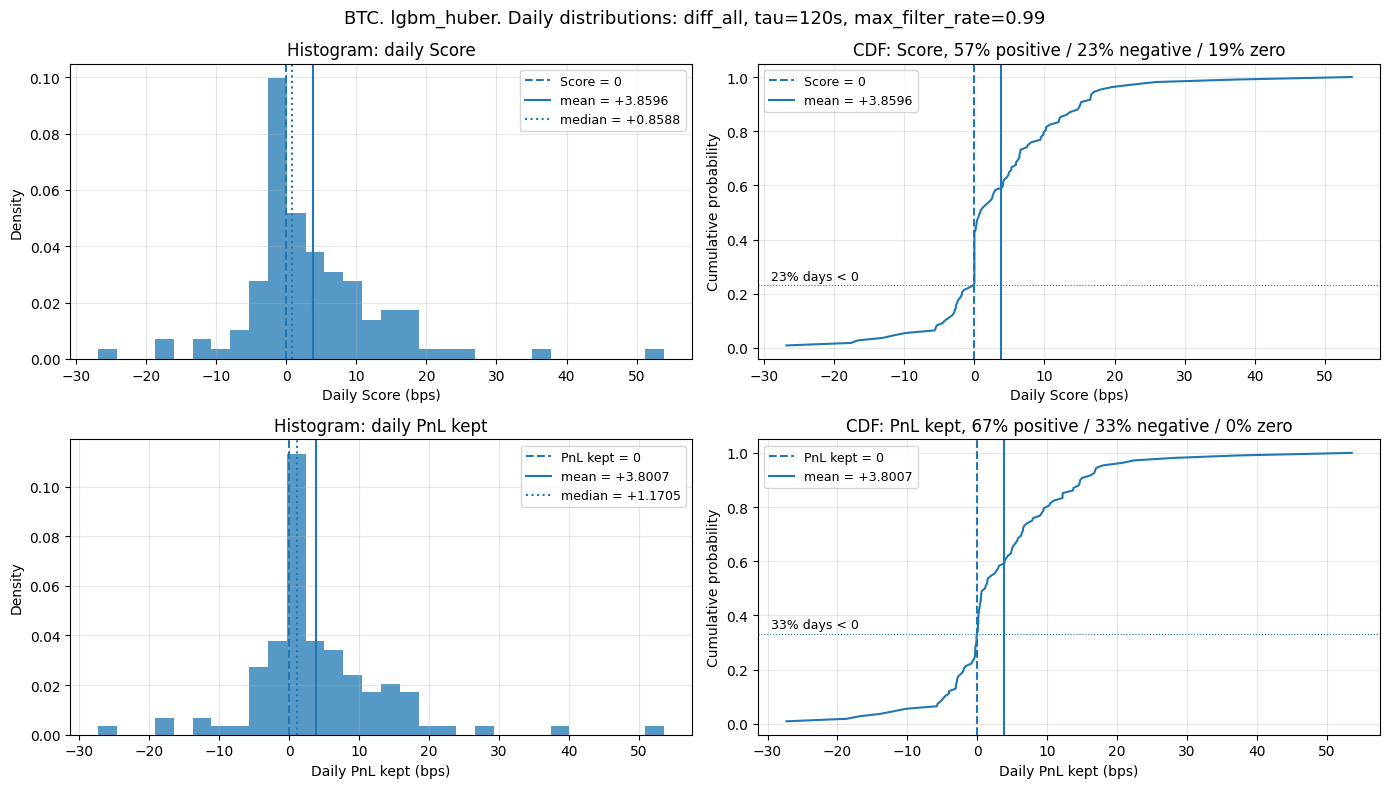

In [24]:
daily = util.plot_daily_score_distribution(
    results         = results_ablation,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)

daily = util.plot_daily_score_distribution(
    results         = results_ablation,
    variant         = "diff_all",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)


## <b>5. Feature importance.</b>

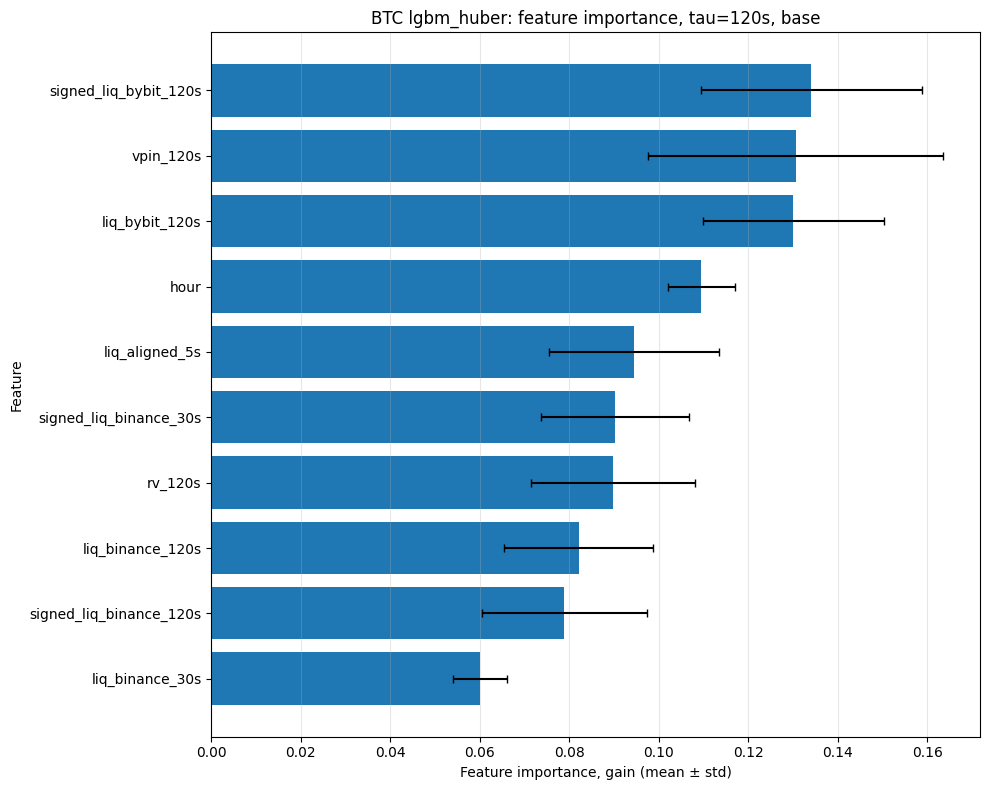

,feature,mean_importance,std_importance,n_models,sem_importance,interval
8,signed_liq_bybit_120s,0.134123,0.024647,5,0.011023,0.024647
9,vpin_120s,0.130570,0.033058,5,0.014784,0.033058
4,liq_bybit_120s,0.130091,0.020258,5,0.009060,0.020258
0,hour,0.109545,0.007485,5,0.003348,0.007485
1,liq_aligned_5s,0.094498,0.019042,5,0.008516,0.019042
7,signed_liq_binance_30s,0.090251,0.016514,5,0.007385,0.016514
5,rv_120s,0.089793,0.018311,5,0.008189,0.018311
2,liq_binance_120s,0.082121,0.016608,5,0.007427,0.016608
6,signed_liq_binance_120s,0.078922,0.018352,5,0.008207,0.018352
3,liq_binance_30s,0.060086,0.006100,5,0.002728,0.006100


In [25]:
tau = 120
variant = "base"
result = results_ablation[("base", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}",
)

display(fi.head(30))

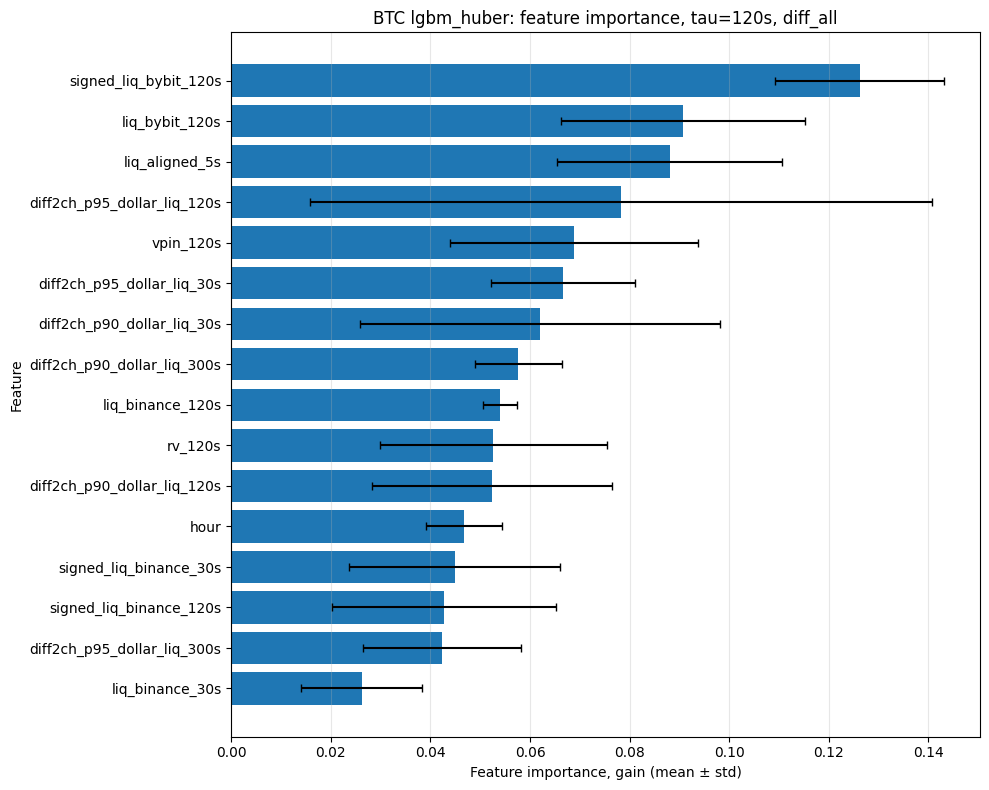

,feature,mean_importance,std_importance,n_models,sem_importance,interval
14,signed_liq_bybit_120s,0.126194,0.017000,5,0.007603,0.017000
10,liq_bybit_120s,0.090662,0.024542,5,0.010976,0.024542
7,liq_aligned_5s,0.088039,0.022616,5,0.010114,0.022616
3,diff2ch_p95_dollar_liq_120s,0.078205,0.062446,5,0.027927,0.062446
15,vpin_120s,0.068851,0.024968,5,0.011166,0.024968
5,diff2ch_p95_dollar_liq_30s,0.066611,0.014419,5,0.006448,0.014419
2,diff2ch_p90_dollar_liq_30s,0.062024,0.036077,5,0.016134,0.036077
1,diff2ch_p90_dollar_liq_300s,0.057660,0.008670,5,0.003878,0.008670
8,liq_binance_120s,0.054005,0.003469,5,0.001552,0.003469
11,rv_120s,0.052634,0.022858,5,0.010222,0.022858


In [26]:
tau = 120
variant = "diff_all"

result = results_ablation[("diff_all", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}",
)

display(fi.head(30))

---
## <b>Executive summary.</b>

The experiment compares two configurations:

- `base` – the top 10 features from the best BTC run;
- `diff_all` – the same top 10 features plus 6 synthetic liquidation features derived from a conditional diffusion model.

All results below are given for `max_filter_rate = 0.99`.

### Base model results

The base model shows the best and most consistent performance over the horizon

$$
\tau = 120s.
$$

The following Score values were obtained for `base`:

tau = 30s:
mean: +0.33 bps

tau = 120s:
mean: +5.15 bps

tau = 300s:
mean: +2.66 bps

The following Score values were obtained for `base + diffusion`:

tau = 30s:
mean: -0.19 bps

tau = 120s:
mean: +5.01 bps

tau = 300s:
mean: +0.68 bps

The strongest result is again obtained at a time horizon of tau=120s. However, unlike ETH, adding diffusion features on BTC does not improve the mean Score at 120s (+5.01 vs +5.15 bps) and degrades it at 30s and 300s.

At the same time, the per-window picture at tau=120s is more nuanced: diffusion features remove the negative window W4 (-0.50 -> +1.07 bps) and substantially improve W3 (+5.69 -> +10.28 bps), but lose part of W2 (+13.84 -> +11.52 bps), and on W5 the filter becomes degenerate (filter_rate = 0, Score = 0). Daily Score statistics at 120s also favor the base model: mean +5.66 vs +3.86 bps, median +5.58 vs +0.86 bps.

Notably, in the `diff_all` model the diffusion features take 6 of the top 11 slots by gain importance (~36% of total gain, with `diff2ch_p95_dollar_liq_120s` the strongest among them), i.e. the model actively uses them - but on BTC this does not translate into a stable OOS improvement. The features contain a signal, but it is unstable and partially redundant with the existing liquidation-flow features.

## <b>A key limitation of the current experiment</b> 

relates to how synthetic features are generated.

The diffusion model does `not generate a forecast for every trade`. Instead, a forecast is generated `only at selected anchor points`. After that, the latest available forecast is applied to the trades using ‘as-of’ logic.

This gives rise to three problems:

1. **Forecast sparsity.**
    - Synthetic features are not available at every point in time as a fresh forecast. Between anchor points, many trades may receive identical diffusion features.
2. **Forecast staleness.**
    - If the most recent forecast point was a long time ago, the features no longer describe the future relative to the current trade, but rather the future relative to an old liquidation anchor. This is particularly critical for long time horizons.
3. **Information degradation.**
    - With this approach, some local information is lost. Instead of an accurate conditional forecast for a specific point in time, the model obtains a coarser, regime-like characterisation.

This explains the deterioration observed on W4 and W5. On W1–W3, synthetic features yield a significant improvement at 120s, but the quality then declines